In [1]:
import json
import os
import subprocess
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Configuration
DISPROT_FOLDER = "disprot-2025_12_12"
TRIZOD_FOLDER = "trizod-2025_12_12"
TRIZOD_FILTERING = "tolerant"
NAN_THRESHOLD = 0.5  # Filter out sequences with too many NaN gscores
MIN_LENGTH = 10
MAX_LENGTH = 1000

In [2]:
# Manually curated list of bad entries, with comments
# This could be automated with some LLM...
EXCLUDED_TRIZOD_ENTRIES = {
    "27269_1_1_1": "reduction with TCEP leads to unfolding",
    "6702_1_1_1": "data is actually from a complex, alone it's an IDP",
}

In [ ]:
# Load trizod data
trizod_data = {}
if not os.path.exists(f"{TRIZOD_FOLDER}/{TRIZOD_FILTERING}.json"):
    raise FileNotFoundError(f"File {TRIZOD_FOLDER}/{TRIZOD_FILTERING}.json not found. It should be crated with TriZOD")
with open(f"{TRIZOD_FOLDER}/{TRIZOD_FILTERING}.json") as f:
    for line in f:
        d = json.loads(line)
        nan_ratio = sum(g is None or (isinstance(g, float) and np.isnan(g)) for g in d["gscores"]) / len(d["gscores"])
        if (
            nan_ratio < NAN_THRESHOLD
            and len(d["seq"]) >= MIN_LENGTH
            and len(d["seq"]) <= MAX_LENGTH
            and d["ID"] not in EXCLUDED_TRIZOD_ENTRIES
        ):
            trizod_data[d["ID"]] = {
                prop: d[prop]
                for prop in ["seq", "entity_name", "temperature", "pH", "ionic_strength", "total_bbshifts", "gscores"]
            }
            trizod_data[d["ID"]]["gscores"] = np.array(trizod_data[d["ID"]]["gscores"], dtype=float)
            trizod_data[d["ID"]]["mean_gscore"] = np.nanmean(trizod_data[d["ID"]]["gscores"])

print(f"Loaded {len(trizod_data):_} trizod entries (filtered from {TRIZOD_FILTERING}.json)")

Loaded 14_792 trizod entries (filtered from tolerant.json)


In [4]:
# Load DisProt data
disprot_filename = "DisProt-release_2025_12-with_ambiguous_evidences.json"
if not os.path.exists(os.path.join(DISPROT_FOLDER, disprot_filename)):
    raise FileNotFoundError(
        f"File {os.path.join(DISPROT_FOLDER, disprot_filename)} not found. It should be downloaded from DisProt website"
    )
with open(os.path.join(DISPROT_FOLDER, disprot_filename), encoding="utf-8") as f:
    disprot_json = json.load(f)

# Fix wrongly assigned disorder_content and build disprot_data dict
disprot_data = {}
for d in disprot_json["data"]:
    if len(d["sequence"]) < MIN_LENGTH or len(d["sequence"]) > MAX_LENGTH:
        continue
    disorder_array = np.zeros(d["length"])
    for annotation in d["disprot_consensus"]["Structural state"]:
        if annotation["type"] == "D":
            disorder_array[annotation["start"] - 1 : annotation["end"]] = 1
    disorder_content = np.mean(disorder_array)
    disprot_data[d["disprot_id"]] = {
        "seq": d["sequence"],
        "disorder_content": disorder_content,
        "mean_gscore": disorder_content,  # Use disorder_content as proxy for mean_gscore
    }

print(f"Loaded {len(disprot_data):_} DisProt entries")

Loaded 2_784 DisProt entries


In [5]:
# Create single clustering file with ALL trizod and disprot entries
combined_fasta = f"{DISPROT_FOLDER}/combined_all.fasta"
combined_cluster = f"{DISPROT_FOLDER}/combined_all_cluster.tsv"

if not os.path.exists(combined_cluster):
    with open(combined_fasta, "w") as f:
        for label, d in trizod_data.items():
            f.write(f">{label}\n{d['seq']}\n")
        for label, d in disprot_data.items():
            f.write(f">{label}\n{d['seq']}\n")

    docker_cmd = [
        "docker",
        "run",
        "--rm",
        "--user",
        f"{os.getuid()}:{os.getgid()}",
        "-v",
        f"{os.path.abspath(DISPROT_FOLDER)}:/data",
        "-w",
        "/data",
        "ghcr.io/soedinglab/mmseqs2",
        "easy-cluster",
        "combined_all.fasta",
        "combined_all",
        "/tmp",
    ]
    subprocess.run(docker_cmd, check=True)
    os.remove(combined_fasta)
    print("Clustering completed.")
else:
    print("Using existing clustering file.")

easy-cluster combined_all.fasta combined_all /tmp 

MMseqs Version:                     	8cc5ce367b5638c4306c2d7cfc652dd099a4643f
Substitution matrix                 	aa:blosum62.out,nucl:nucleotide.out
Seed substitution matrix            	aa:VTML80.out,nucl:nucleotide.out
Sensitivity                         	4
k-mer length                        	0
Target search mode                  	0
k-score                             	seq:2147483647,prof:2147483647
Alphabet size                       	aa:21,nucl:5
Max sequence length                 	65535
Max results per query               	20
Split database                      	0
Split mode                          	2
Split memory limit                  	0
Coverage threshold                  	0.8
Coverage mode                       	0
Compositional bias                  	1
Compositional bias scale            	1
Diagonal scoring                    	true
Exact k-mer matching                	0
Mask residues                       	1
Mask residues

Converting sequences
[=
Time for merging to input_h: 0h 0m 0s 0ms
Time for merging to input: 0h 0m 0s 0ms
Database type: Aminoacid
Time for processing: 0h 0m 0s 10ms
Create directory /tmp/1809596970511904597/clu_tmp
cluster /tmp/1809596970511904597/input /tmp/1809596970511904597/clu /tmp/1809596970511904597/clu_tmp --max-seqs 20 -c 0.8 --spaced-kmer-mode 1 --alignment-mode 3 -e 0.001 --remove-tmp-files 1 

Set cluster sensitivity to -s 6.000000
Set cluster mode SET COVER
Set cluster iterations to 3
linclust /tmp/1809596970511904597/input /tmp/1809596970511904597/clu_tmp/12439414210564493613/clu_redundancy /tmp/1809596970511904597/clu_tmp/12439414210564493613/linclust --cluster-mode 0 --max-iterations 1000 --similarity-type 2 --threads 20 --compressed 0 -v 3 --cluster-weight-threshold 0.9 --sub-mat 'aa:blosum62.out,nucl:nucleotide.out' -a 0 --alignment-mode 3 --alignment-output-mode 0 --wrapped-scoring 0 -e 0.001 --min-seq-id 0 --min-aln-len 0 --seq-id-mode 0 --alt-ali 0 -c 0.8 --cov-mo

Total clusters: 8_745
Total entries: 17_576


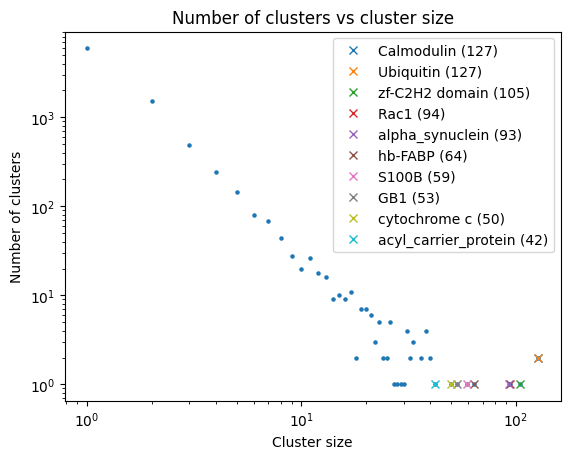

In [6]:
# Load clusters and compute cluster sizes
clusters_df = pd.read_csv(combined_cluster, sep="\t", names=["representative", "member"])
cluster_sizes = clusters_df.groupby("representative").size()
clusters_df["cluster_size"] = clusters_df["representative"].map(cluster_sizes)

# Get best entity name for each cluster (from trizod entries)
best_entity_name = {}
for rep in clusters_df["representative"].unique():
    members = clusters_df[clusters_df["representative"] == rep]["member"]
    entity_names = [trizod_data[m]["entity_name"].strip().replace("\n", " ") for m in members if m in trizod_data]
    meaningful_names = [n for n in entity_names if n and "entity" not in n.lower()]
    if meaningful_names:
        best_entity_name[rep] = Counter(meaningful_names).most_common(1)[0][0]
    elif entity_names:
        best_entity_name[rep] = Counter(entity_names).most_common(1)[0][0]
    else:
        best_entity_name[rep] = ""
clusters_df["best_entity_name"] = clusters_df["representative"].map(lambda rep: best_entity_name[rep])

print(f"Total clusters: {len(clusters_df['representative'].unique()):_}")
print(f"Total entries: {len(clusters_df):_}")

n_top = 10
top_n_clusters = cluster_sizes.nlargest(n_top).sort_values()
top_n_names = [best_entity_name[rep] for rep in top_n_clusters.index]
cluster_size_counts = cluster_sizes.value_counts().sort_index()
plt.scatter(cluster_size_counts.index, cluster_size_counts.values, s=5)
plt.title("Number of clusters vs cluster size")
plt.xlabel("Cluster size")
plt.ylabel("Number of clusters")
plt.yscale("log")
plt.xscale("log")

# Annotate the top_n clusters on the plot
for name, size in reversed(list(zip(top_n_names, top_n_clusters.values, strict=False))):
    plt.plot(size, cluster_size_counts[size], "x", label=f"{name} ({size:_})")
plt.legend()
plt.show()

In [7]:
def get_mean_disorder(label: str) -> float:
    """Get mean disorder score for a label (trizod or disprot)."""
    if label in trizod_data:
        return trizod_data[label]["mean_gscore"]
    elif label in disprot_data:
        return disprot_data[label]["disorder_content"]
    return np.nan


def get_conditions_score(label: str, cluster_mean_disorder: float, disprot_penalty: float = 1000) -> float:
    """Score for selecting representative. Lower is better.

    Includes:
    - Distance from standard conditions (temperature, pH, ionic strength)
    - Penalty for NaN gscores
    - Distance from cluster average disorder
    """
    if label in trizod_data:
        d = trizod_data[label]
        delta_temperature = (d["temperature"] - 298.0) / 15.0
        delta_pH = (d["pH"] - 7.4) / 1.5
        delta_ionic_strength = (d["ionic_strength"] - 0.1) / 3
        nan_penalty = 5 * np.isnan(d["gscores"]).sum() / len(d["gscores"])
        disorder_distance = 4 * abs(d["mean_gscore"] - cluster_mean_disorder)
        return np.linalg.norm([delta_temperature, delta_pH, delta_ionic_strength]) + nan_penalty + disorder_distance
    elif label in disprot_data:
        # DisProt entries: only disorder distance matters (no experimental conditions)
        disorder_distance = 4 * abs(disprot_data[label]["disorder_content"] - cluster_mean_disorder)
        return disorder_distance + disprot_penalty  # never pick DisProt entries if trizod are available
    return np.inf

In [8]:
# Compute cluster average disorder and score for each member
clusters_df["mean_disorder"] = clusters_df["member"].map(get_mean_disorder)
cluster_avg_disorder = clusters_df.groupby("representative")["mean_disorder"].mean()
clusters_df["cluster_avg_disorder"] = clusters_df["representative"].map(cluster_avg_disorder)

clusters_df["score"] = clusters_df.apply(
    lambda row: get_conditions_score(row["member"], row["cluster_avg_disorder"]),
    axis=1,
)


# Select best representative per cluster (lowest score, must be in same group as original rep)
def select_best_representative(group, same_seq_only=False):
    if same_seq_only:
        rep = group.name
        rep_seq = trizod_data[rep]["seq"] if rep in trizod_data else disprot_data[rep]["seq"]

        # Filter to members with same sequence as representative
        same_seq_mask = group["member"].apply(
            lambda m: (trizod_data[m]["seq"] if m in trizod_data else disprot_data[m]["seq"]) == rep_seq,
        )
        if same_seq_mask.any():
            same_seq_group = group.loc[same_seq_mask]
            return same_seq_group["member"].iloc[same_seq_group["score"].argmin()]

    return group["member"].iloc[group["score"].argmin()]


best_representatives = clusters_df.groupby("representative").apply(select_best_representative, include_groups=False)
clusters_df["best_representative"] = clusters_df["representative"].map(best_representatives)

rep_pairs = clusters_df[["representative", "best_representative"]].drop_duplicates()
n_changed = int((rep_pairs["representative"] != rep_pairs["best_representative"]).sum())
print(f"Changed {n_changed:_} representatives out of {len(rep_pairs):_}")

Changed 1_531 representatives out of 8_745


In [9]:
# Find shared clusters (have both trizod and disprot members) and check for controversial entries
has_disprot = clusters_df.groupby("representative")["member"].apply(lambda x: x.str.startswith("DP").any())
has_trizod = clusters_df.groupby("representative")["member"].apply(lambda x: (~x.str.startswith("DP")).any())
shared_clusters = has_disprot & has_trizod

# Compute mean gscore (trizod) and disorder content (disprot) per shared cluster
shared_df = clusters_df[clusters_df["representative"].isin(shared_clusters[shared_clusters].index)].copy()

cluster_stats = []
for rep, group in shared_df.groupby("representative"):
    if best_representatives[rep] in trizod_data:
        best_gscore = trizod_data[best_representatives[rep]]["mean_gscore"]
    else:
        best_gscore = np.nan
    trizod_gscores = [trizod_data[m]["mean_gscore"] for m in group["member"] if m in trizod_data]
    disprot_disorders = [disprot_data[m]["disorder_content"] for m in group["member"] if m in disprot_data]
    trizod_members = [m for m in group["member"] if m in trizod_data]
    disprot_members = [m for m in group["member"] if m in disprot_data]
    if trizod_gscores and disprot_disorders:
        cluster_stats.append(
            {
                "representative": rep,
                "mean_gscore": np.mean(trizod_gscores),
                "disorder_content": np.mean(disprot_disorders),
                "trizod_members": trizod_members,
                "disprot_members": disprot_members,
                "best_representative": best_representatives[rep],
                "best_gscore": best_gscore,
            },
        )

stats_df = pd.DataFrame(cluster_stats)
print(f"Shared clusters (both trizod and disprot): {len(stats_df)}")

Shared clusters (both trizod and disprot): 315


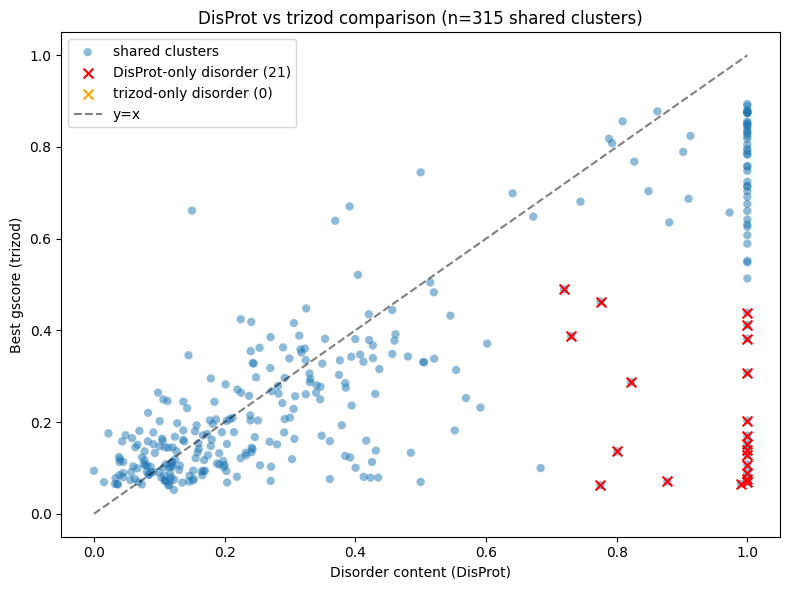

In [10]:
# Plot to identify controversial entries and automatically exclude them
unc_region = 0.2
mean_gscores = stats_df["mean_gscore"].values
best_gscores = stats_df["best_gscore"].values
disorder_contents = stats_df["disorder_content"].values

# Controversial: DisProt says highly disordered but trizod says structured
disprot_only_disorder = (best_gscores < 0.5) & (disorder_contents >= 0.5 + unc_region)
# Also flag: trizod says disordered but disprot says structured (less common)
trizod_only_disorder = (best_gscores >= 0.5 + unc_region) & (disorder_contents < 0.5)

plt.figure(figsize=(8, 6))
plt.scatter(disorder_contents, best_gscores, alpha=0.5, edgecolors="none", label="shared clusters")
plt.scatter(
    disorder_contents[disprot_only_disorder],
    best_gscores[disprot_only_disorder],
    marker="x",
    c="red",
    s=50,
    label=f"DisProt-only disorder ({sum(disprot_only_disorder)})",
)
plt.scatter(
    disorder_contents[trizod_only_disorder],
    best_gscores[trizod_only_disorder],
    marker="x",
    c="orange",
    s=50,
    label=f"trizod-only disorder ({sum(trizod_only_disorder)})",
)
plt.plot([0, 1], [0, 1], "k--", alpha=0.5, label="y=x")
plt.xlabel("Disorder content (DisProt)")
plt.ylabel("Best gscore (trizod)")
plt.title(f"DisProt vs trizod comparison (n={len(stats_df)} shared clusters)")
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# Identify and remove controversial trizod entries (DisProt annotations more reliable for disorder)
# Use stricter threshold for automatic removal: disprot says >80% disordered, trizod says <50%
mask = (disorder_contents > 0.8) & (best_gscores < 0.5)
wrong_trizod = []
wrong_trizod_file = f"{DISPROT_FOLDER}/controversial_trizod_entries.log"

print("Controversial entries (will be removed from trizod):")
with open(wrong_trizod_file, "w") as f:
    f.write("Controversial entries (will be removed from trizod):\n")
    for i in np.where(mask)[0]:
        row = stats_df.iloc[i]
        line = f"  {best_entity_name[row['representative']]: <20} -- "
        line += f"disorder_content: {row['disorder_content']:.2f}, best_gscore: {row['best_gscore']:.3f}, mean_gscore: {row['mean_gscore']:.3f}, "
        line += f"DisProt: {row['disprot_members']}, trizod: {row['trizod_members']}"
        print(line)
        f.write(line + "\n")
        wrong_trizod.extend(row["trizod_members"])

print(f"\nRemoving {len(wrong_trizod)} controversial trizod entries")

# Clean clusters and trizod data
cleaned_clusters_df = clusters_df[~clusters_df["member"].isin(wrong_trizod)].copy()
cleaned_best_representatives = cleaned_clusters_df.groupby("representative").apply(
    select_best_representative,
    include_groups=False,
)
cleaned_clusters_df["best_representative"] = cleaned_clusters_df["representative"].map(cleaned_best_representatives)

Controversial entries (will be removed from trizod):
  C2 domain            -- disorder_content: 0.80, best_gscore: 0.136, mean_gscore: 0.135, DisProt: ['DP03647'], trizod: ['10073_1_1_1', '36129_1_1_1']
  Cox17                -- disorder_content: 1.00, best_gscore: 0.382, mean_gscore: 0.462, DisProt: ['DP00543'], trizod: ['11020_1_1_1', '17821_1_1_1', '17067_1_2_2', '11019_1_1_1']
  MCFD2                -- disorder_content: 0.82, best_gscore: 0.287, mean_gscore: 0.266, DisProt: ['DP01637'], trizod: ['15789_2_1_1', '15789_1_1_1']
  entity_1             -- disorder_content: 1.00, best_gscore: 0.077, mean_gscore: 0.189, DisProt: ['DP03818'], trizod: ['21008_1_1_1', '31100_1_1_1', '34283_1_1_1', '31173_1_1_1', '34367_1_1_1', '34366_1_1_1']
  hb-FABP              -- disorder_content: 1.00, best_gscore: 0.069, mean_gscore: 0.070, DisProt: ['DP00340'], trizod: ['27113_1_1_1', '27112_1_1_1', '5541_1_1_1', '16046_1_1_1', '16049_1_1_1', '5320_1_1_1', '16048_1_1_1', '16047_1_1_1', '16042_1_1_1',

In [12]:
# Compute disorder class per cluster: 0=ordered, 1=disordered, 2=uncertain/mixed
std_disorder_threshold = 0.25
mean_disorder_threshold = 0.5
buffer_disorder_threshold = 0.2

classes = {}  # 0=ordered, 1=disordered, 2=uncertain/mixed
for rep, group in cleaned_clusters_df.groupby("best_representative"):
    mean_dis = []
    std_dis = []
    sure_dis = False
    for label in group["member"]:
        if label in disprot_data:
            mean_dis.append(disprot_data[label]["disorder_content"])
            if mean_dis[-1] > 0.9:  # trust clear human annotations
                sure_dis = True
                break
        elif label in trizod_data:
            mean_dis.append(trizod_data[label]["mean_gscore"])
            std_dis.append(np.nanstd(trizod_data[label]["gscores"]))
    if sure_dis:
        classes[rep] = 1
    elif (
        (std_dis and np.mean(std_dis) > std_disorder_threshold)
        or (np.std(mean_dis) > std_disorder_threshold)
        or (np.abs(np.mean(mean_dis) - mean_disorder_threshold) < buffer_disorder_threshold)
    ):
        classes[rep] = 2
    else:
        classes[rep] = int(np.mean(mean_dis) >= mean_disorder_threshold)

counts = np.bincount(list(classes.values()))
print(f"Class distribution:\n0 (ordered): {counts[0]:_}\n1 (disordered): {counts[1]:_}\n2 (uncertain): {counts[2]:_}")

Class distribution:
0 (ordered): 6_221
1 (disordered): 685
2 (uncertain): 1_839


In [13]:
# Check CheZOD overlap to exclude from test set
CHEZOD_FOLDER = "chezod"

chezod_cluster_file = f"{CHEZOD_FOLDER}/all_combined_cluster.tsv"
if not os.path.exists(chezod_cluster_file):
    chezod_file = f"{CHEZOD_FOLDER}/allseqs1325.txt"
    if not os.path.exists(chezod_file):
        import requests, tarfile

        os.makedirs(CHEZOD_FOLDER, exist_ok=True)
        url = "https://github.com/protein-nmr/CheZOD/raw/refs/heads/master/CheZOD1325.tar.gz"
        with open(os.path.basename(url), "wb") as f:
            f.write(requests.get(url).content)
        with tarfile.open(os.path.basename(url), "r:gz") as tar:
            tar.extractall(CHEZOD_FOLDER)
        os.remove(os.path.basename(url))
    df_chezod = pd.read_csv(chezod_file, sep=r"\s+", names=["label", "sequence"]).drop_duplicates(["sequence"])
    print(f"unique CheZOD sequences: {len(df_chezod):_}")
    chezod_fasta = f"{CHEZOD_FOLDER}/all_combined.fasta"
    with open(chezod_fasta, "w") as f:
        for label, seq in df_chezod.itertuples(index=False):
            f.write(f">chezod_{label}\n{seq}\n")
        for rep in cleaned_clusters_df["best_representative"].unique():
            seq = trizod_data[rep]["seq"] if rep in trizod_data else disprot_data[rep]["seq"]
            f.write(f">{rep}\n{seq}\n")

    docker_cmd = [
        "docker",
        "run",
        "--rm",
        "--user",
        f"{os.getuid()}:{os.getgid()}",
        "-v",
        f"{os.path.abspath(CHEZOD_FOLDER)}:/data",
        "-w",
        "/data",
        "ghcr.io/soedinglab/mmseqs2",
        "easy-cluster",
        "all_combined.fasta",
        "all_combined",
        "/tmp",
    ]
    subprocess.run(docker_cmd, check=True)
    os.remove(chezod_fasta)

chezod_clusters_df = pd.read_csv(chezod_cluster_file, sep="\t", names=["representative", "member"])
has_chezod = chezod_clusters_df.groupby("representative")["member"].apply(lambda x: x.str.startswith("chezod_").any())
chezod_overlapping_labels = (
    chezod_clusters_df[chezod_clusters_df["representative"].isin(has_chezod[has_chezod].index)][
        ~chezod_clusters_df["member"].str.startswith("chezod_")
    ]["member"]
    .unique()
    .tolist()
)
print(f"Labels overlapping with CheZOD: {len(chezod_overlapping_labels)}")

unique CheZOD sequences: 1_322
easy-cluster all_combined.fasta all_combined /tmp 

MMseqs Version:                     	8cc5ce367b5638c4306c2d7cfc652dd099a4643f
Substitution matrix                 	aa:blosum62.out,nucl:nucleotide.out
Seed substitution matrix            	aa:VTML80.out,nucl:nucleotide.out
Sensitivity                         	4
k-mer length                        	0
Target search mode                  	0
k-score                             	seq:2147483647,prof:2147483647
Alphabet size                       	aa:21,nucl:5
Max sequence length                 	65535
Max results per query               	20
Split database                      	0
Split mode                          	2
Split memory limit                  	0
Coverage threshold                  	0.8
Coverage mode                       	0
Compositional bias                  	1
Compositional bias scale            	1
Diagonal scoring                    	true
Exact k-mer matching                	0
Mask residues        

/tmp/ipykernel_616343/406301965.py:49: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  chezod_clusters_df[chezod_clusters_df["representative"].isin(has_chezod[has_chezod].index)][


In [14]:
cleaned_clusters_df

,representative,member,cluster_size,best_entity_name,mean_disorder,cluster_avg_disorder,score,best_representative
0,28079_1_1_1,28079_1_1_1,5,teEIC,0.062905,0.064926,1.801337,50695_1_1_1
1,28079_1_1_1,28080_1_1_1,5,teEIC,0.063950,0.064926,1.718345,50695_1_1_1
2,28079_1_1_1,50695_1_1_1,5,teEIC,0.068508,0.064926,1.093693,50695_1_1_1
3,28079_1_1_1,50694_1_1_1,5,teEIC,0.071986,0.064926,1.504430,50695_1_1_1
4,28079_1_1_1,18392_1_1_1,5,teEIC,0.057283,0.064926,1.902935,50695_1_1_1
...,...,...,...,...,...,...,...,...
17571,15871_1_1_1,15871_1_1_1,1,XACb0070,0.110636,0.110636,1.230359,15871_1_1_1
17572,53231_1_1_1,53231_1_1_1,4,DUSP22,0.070858,0.076474,1.714013,50156_1_1_1
17573,53231_1_1_1,50156_1_1_1,4,DUSP22,0.075332,0.076474,0.557861,50156_1_1_1
17574,53231_1_1_1,5000_1_1_1,4,DUSP22,0.076222,0.076474,0.826539,50156_1_1_1


In [15]:
# Create trizod DataFrame for export
trizod_df = pd.DataFrame(
    [
        {
            "label": label,
            "entity_name": cleaned_clusters_df[cleaned_clusters_df["best_representative"] == label]["best_entity_name"]
            .iloc[0]
            .replace(",", "")
            .replace("\n", ""),
            "cluster_size": len(
                [
                    m
                    for m in cleaned_clusters_df[cleaned_clusters_df["best_representative"] == label]["member"]
                    if m in trizod_data
                ],
            ),
            "sequence": trizod_data[label]["seq"],
            "temperature": trizod_data[label]["temperature"],
            "pH": trizod_data[label]["pH"],
            "ionic_strength": trizod_data[label]["ionic_strength"],
            "total_bbshifts": trizod_data[label]["total_bbshifts"],
            "mean_gscore": trizod_data[label]["mean_gscore"],
            "gscores": json.dumps(trizod_data[label]["gscores"].tolist()),
        }
        for label in sorted(cleaned_clusters_df["best_representative"].unique(), key=lambda x: (len(x), x))
        if label in trizod_data
    ],
).set_index("label")

# Define balanced test set (without CheZOD overlap)
np.random.seed(883)
test_percentage = 0.1
dis_mask = trizod_df["mean_gscore"] >= 0.5
half_test = int(sum(dis_mask) * test_percentage)
chezod_overlap_mask = trizod_df.index.isin(chezod_overlapping_labels)

test_indexes = np.concatenate(
    [
        np.random.choice(trizod_df.index[(dis_mask) & (~chezod_overlap_mask)], size=half_test, replace=False),
        np.random.choice(trizod_df.index[(~dis_mask) & (~chezod_overlap_mask)], size=half_test, replace=False),
    ],
)

trizod_df.insert(0, "is_test", trizod_df.index.isin(test_indexes))
print(f"Test set size: {sum(trizod_df['is_test'])} ({half_test} disordered + {half_test} ordered)")
trizod_df.to_csv("cleaned_trizod_dataset.csv")
print(f"Saved cleaned_trizod_dataset.csv with {len(trizod_df):_} entries")

Test set size: 158 (79 disordered + 79 ordered)
Saved cleaned_trizod_dataset.csv with 6_789 entries


In [16]:
# Save st_classes.csv (one row per cluster representative)
with open("st_classes.csv", "w") as f:
    f.write("label,is_test,class,sequence\n")
    for rep in sorted(cleaned_clusters_df["best_representative"].unique(), key=lambda x: (len(x), x)):
        is_test = rep in test_indexes
        seq = trizod_data[rep]["seq"] if rep in trizod_data else disprot_data[rep]["seq"]
        f.write(f"{rep},{is_test},{classes[rep]},{seq}\n")

classes_df = pd.read_csv("st_classes.csv")
print(f"Saved st_classes.csv with {len(classes_df)} cluster representatives")
print(f"  Test clusters: {sum(classes_df['is_test'])}")
print(f"  Class distribution: {dict(classes_df['class'].value_counts().sort_index())}")

Saved st_classes.csv with 8745 cluster representatives
  Test clusters: 158
  Class distribution: {0: np.int64(6221), 1: np.int64(685), 2: np.int64(1839)}
